# School Experiences and Student Mental Health: An Analysis of the 2025 National YRBS

## Introduction

Students' experiences at school extend beyond academic performance. Their relationships with peers, sense of belonging, and perceptions of safety are important aspects of the school environment that may be associated with their mental health. Understanding these relationships can help educators identify challenges that students face and make more informed decisions about how to support them.

This project explores the relationship between school experiences and mental health among U.S. high school students using data from the CDC's 2025 National Youth Risk Behavior Survey (YRBS). Specifically, I examine how school connectedness, bullying, and safety-related absences are associated with students' reports of persistent sadness or hopelessness and poor mental health.

Through data cleaning, exploratory data analysis, visualization, and statistical hypothesis testing, I aim to identify patterns in students' reported experiences and consider how these findings could inform school climate discussions and further investigation.

## Data Preparation and Exploration

### Data Source and Preparation

This project uses data from the Centers for Disease Control and Prevention's (CDC) 2025 National Youth Risk Behavior Survey (YRBS), which collects information about health-related behaviors and experiences among U.S. high school students.

The dataset was originally downloaded as a fixed-width .dat file. Unlike a CSV, a fixed-width file stores variables in predetermined character positions rather than separating them with commas.

To make the data easier to analyze in Python, I used the CDC's accompanying SAS Input Program, which identifies the starting positions and lengths of each variable, to convert the original file into CSV format.

I then imported the resulting CSV into Python using the pandas library.

In [1]:
import pandas as pd

yrbs = pd.read_csv(
    "2025_national_YRBS_parsed.csv",
    low_memory=False
)
yrbs.head()

,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,QNOBESE,QNOWT,WEIGHT,STRATUM,PSU,BMIPCT,RACEETH,Q5ORIG,Q6ORIG,RECORD
0,3.0,1.0,1.0,G,1.57,48.99,5.0,1.0,1.0,1.0,...,2.0,2.0,2.5056,214,57902,53.32,7.0,502,108,1
1,3.0,2.0,1.0,G,1.80,54.43,5.0,1.0,1.0,1.0,...,2.0,2.0,1.3947,214,57902,9.85,7.0,511,120,2
2,3.0,1.0,1.0,D G,1.63,49.90,4.0,3.0,1.0,1.0,...,2.0,2.0,1.5218,214,57902,38.08,8.0,504,110,3
3,4.0,1.0,1.0,G,1.60,44.45,4.0,1.0,1.0,1.0,...,2.0,2.0,2.5056,214,57902,11.99,7.0,503,98,4
4,4.0,2.0,1.0,C,1.83,60.33,3.0,1.0,1.0,1.0,...,2.0,2.0,0.7270,214,57902,17.10,3.0,600,133,5


### Selecting and Exploring Variables

I am interested in exploring the relationship between students' experiences at school and their mental health. Using the CDC's 2025 YRBS questionnaire to identify the survey questions associated with each variable, I selected six variables for an initial exploration:

- **Q13:** Missing school because of safety concerns

- **Q26:** Bullied on school property

- **Q27:** Bullied electronically

- **Q29:** Persistent sadness or hopelessness

- **Q81:** Frequency of poor mental health

- **Q102:** Feeling close to people at school (i.e. school connectedness)

Although the questionnaire and dataset refer to the same survey, their question numbering differs. I used the CDC's Data User's Guide to match each survey question to its corresponding dataset variable. The analysis below uses the dataset variable names.

I will begin by examining the first ten observations for these variables to understand how the responses are structured, identify missing values, and prepare for further analysis.

In [2]:
variables = ["Q13", "Q23", "Q24", "Q26", "Q81", "Q102"]

labels = {
    "Q13": "School safety concerns",
    "Q23": "In-person bullying",
    "Q24": "Electronic bullying",
    "Q26": "Persistent sadness/hopelessness",
    "Q81": "Poor mental health",
    "Q102": "School connectedness"
}

yrbs[variables].head(10)

,Q13,Q23,Q24,Q26,Q81,Q102
0,1.0,2.0,2.0,1.0,4.0,3.0
1,1.0,NaN,1.0,2.0,3.0,2.0
2,1.0,2.0,2.0,2.0,4.0,2.0
3,2.0,2.0,1.0,2.0,4.0,4.0
4,1.0,2.0,2.0,2.0,1.0,2.0
5,1.0,2.0,2.0,2.0,2.0,2.0
6,1.0,2.0,2.0,2.0,3.0,3.0
7,1.0,2.0,2.0,NaN,3.0,3.0
8,1.0,2.0,2.0,2.0,3.0,4.0
9,1.0,1.0,2.0,2.0,3.0,2.0


### Assessing Missing Data

First, I am checking the completeness of the responses for the selected variables before deciding how to handle missing ones.

In [3]:
missing = yrbs[variables].isna().sum()

missing_table = pd.DataFrame({
    "Missing": missing,
    "Percentage": (missing / len(yrbs) * 100).round(1)
})

missing_table = missing_table.rename(index=labels)
missing_table


,Missing,Percentage
School safety concerns,62,0.6
In-person bullying,53,0.5
Electronic bullying,62,0.6
Persistent sadness/hopelessness,227,2.1
Poor mental health,1908,17.8
School connectedness,1289,12.0


The questions related to school safety, bullying, and persistent sadness or hopelessness have relatively low rates of missing responses, ranging from 0.5% to 2.1%. However, Question 102, which measures school connectedness, has a missing response rate of 12.0%, while Question 81, which measures the frequency of poor mental health, has a higher rate of 17.8%.

Next, I will investigate whether missing responses to Questions 92 and 102 are associated. This may help identify patterns in the missing data before deciding how to handle these observations.

In [4]:
pd.crosstab(
    yrbs["Q81"].isna(),
    yrbs["Q102"].isna()
)

Q102,False,True
Q81,,
False,8113,689
True,1308,600


The cross-tabulation shows that 8,113 students answered both questions, while 600 students answered neither. Additionally, 689 students answered the poor mental health question (Q81) but not the school connectedness question (Q102), and 1,308 answered the school connectedness question but not the poor mental health question.

To investigate this further, I will calculate the percentage of students who did not answer the poor mental health question (Q81) but did answer the school connectedness question (Q102), which appears later in the questionnaire.

In [41]:
q81_missing = yrbs["Q81"].isna()
q102_answered = yrbs["Q102"].notna()

percentage = (q81_missing & q102_answered).sum() / q81_missing.sum() * 100

round(percentage, 1)

np.float64(68.6)

Of the 1,908 students missing a response to the poor mental health question (Q81), 68.6% (1,308 students) provided a response to the school connectedness question (Q102). This suggests that missing mental health responses cannot be explained solely by students abandoning the survey before reaching the school connectedness question.

However, this does not explain why 17.8% of students are missing responses to the poor mental health question. Further investigation into the CDC's survey methodology and documentation is needed before determining how to handle these missing values.

According to the CDC's 2025 YRBS Data User's Guide (pp. 4–7), responses may be coded as missing when they are invalid, contain multiple selections, or conflict with other responses under specified logical consistency rules.

These procedures explain some potential sources of missing data, but they do not fully account for the 17.8% missing response rate for poor mental health. The cause of this missingness remains undetermined, so I will consider its potential impact when selecting variables and interpreting the results.

Since the CDC's documentation does not fully explain the missing response rate for poor mental health, I will investigate whether missingness varies by grade level. This may help determine whether missing responses are distributed similarly across grades or concentrated among particular groups of students.

#### Assessing Missing Responses by Grade Level

In [6]:
yrbs.groupby("Q3")["Q81"].apply(lambda x: x.isna().mean() * 100).round(1)

Q3
1.0    20.9
2.0    18.6
3.0    15.1
4.0    15.6
5.0    15.8
Name: Q81, dtype: float64

In [7]:
yrbs["Q3"].value_counts().sort_index()

Q3
1.0    3086
2.0    2763
3.0    2610
4.0    2209
5.0      19
Name: count, dtype: int64

Missing responses to the poor mental health question (Q81) range from 15.1% to 20.9% among students in grades 9–12, with higher missing response rates in 9th grade (20.9%) and 10th grade (18.6%) than in 11th grade (15.1%) and 12th grade (15.6%). The fifth grade category has a missing response rate of 15.8%, but this group contains only 19 students, making its percentage less reliable for comparison.

These results suggest that missing responses to the poor mental health question are somewhat more common among younger high school students, although missingness occurs across all grade levels. The reason for this pattern remains unclear.

#### Assessing Missing Responses By Race

In [8]:
yrbs.groupby("RACEETH")["Q81"].apply(
    lambda x: x.isna().mean() * 100
).round(1)

RACEETH
1.0    23.1
2.0    14.3
3.0    14.1
4.0    17.7
5.0    14.4
6.0    39.4
7.0    18.9
8.0    23.3
9.0    17.0
Name: Q81, dtype: float64

In [9]:
yrbs["RACEETH"].value_counts().sort_index()

RACEETH
1.0      78
2.0     517
3.0    2169
4.0    2399
5.0     104
6.0      33
7.0    3603
8.0     954
9.0     760
Name: count, dtype: int64

To investigate whether missing responses to the poor mental health question (Q81) vary across demographic groups, I examined missing response rates by race/ethnicity and checked the number of students in each group.

Missing response rates range from 14.1% to 39.4%, suggesting that missingness is not evenly distributed across racial and ethnic groups. Native Hawaiian or Pacific Islander students have the highest missing response rate (39.4%), although this group contains only 33 students. American Indian or Alaska Native students also have a relatively high missing response rate (23.1%), but this group contains only 78 students. The Middle Eastern or North African group is also relatively small, with 104 students.

These differences suggest that missingness may be associated with race/ethnicity, although the small sample sizes in some groups limit the conclusions that can be drawn. I will consider these patterns when deciding how to handle missing responses and interpreting the results.

### Cleaning and Recoding Responses

Before cleaning the data, I will examine the unique response values for each selected variable and compare them with the response categories documented in the CDC's Data User's Guide. This will help identify invalid values and determine which variables need to be recoded for analysis.

In [10]:
for variable in variables:
    print(f"{variable}: {sorted(yrbs[variable].dropna().unique())}")

Q13: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
Q23: [np.float64(1.0), np.float64(2.0)]
Q24: [np.float64(1.0), np.float64(2.0)]
Q26: [np.float64(1.0), np.float64(2.0)]
Q81: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
Q102: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


The observed response values fall within the expected ranges documented in the CDC's Data User's Guide, so no additional invalid numeric values were identified. However, some variables need to be recoded to make their responses easier to interpret and compare.

#### Missing School Because of Safety Concerns

I will begin by recoding school safety concerns (Q13) as a binary variable indicating whether a student missed school at least once because they felt unsafe. A value of 1 will indicate at least one absence due to safety concerns, while 0 will indicate no such absences. Missing responses will be preserved.

In [12]:
yrbs["missed_school_unsafe"] = yrbs["Q13"].map({
    1: 0,  # 0 days
    2: 1,  # 1 day
    3: 1,  # 2 or 3 days
    4: 1,  # 4 or 5 days
    5: 1   # 6 or more days
})

yrbs["missed_school_unsafe"].value_counts(dropna=False)

missed_school_unsafe
0.0    9335
1.0    1313
NaN      62
Name: count, dtype: int64

#### Bullying on School Property

Next, I will recode in-person bullying (Q23) as a binary variable, where 1 indicates that a student experienced bullying at school and 0 indicates that they did not. Missing responses will be preserved.

In [14]:
yrbs["bullied_at_school"] = yrbs["Q23"].map({
    1: 1,  # Yes
    2: 0   # No
})

yrbs["bullied_at_school"].value_counts(dropna=False)

bullied_at_school
0.0    8700
1.0    1957
NaN      53
Name: count, dtype: int64

#### Bullying Electronically

Now, I will recode electronic bullying (Q24) as a binary variable using the same approach as in-person bullying. A value of 1 will indicate that a student experienced electronic bullying, while 0 will indicate that they did not. Missing responses will be preserved.

In [16]:
yrbs["bullied_electronically"] = yrbs["Q24"].map({
    1: 1,  # Yes
    2: 0   # No
})

yrbs["bullied_electronically"].value_counts(dropna=False)

bullied_electronically
0.0    9213
1.0    1435
NaN      62
Name: count, dtype: int64

#### Persistent Sadness or Hopelessness

Next, I will recode persistent sadness or hopelessness (Q26) as a binary variable, where 1 indicates that a student experienced persistent feelings of sadness or hopelessness and 0 indicates that they did not. Missing responses will be preserved.

In [18]:
yrbs["persistent_sadness"] = yrbs["Q26"].map({
    1: 1,  # Yes
    2: 0   # No
})

yrbs["persistent_sadness"].value_counts(dropna=False)

persistent_sadness
0.0    6860
1.0    3623
NaN     227
Name: count, dtype: int64

#### Poor Mental Health

Unlike the previous variables, poor mental health (Q81) has five ordered response categories ranging from "Never" to "Always." I will retain these categories to preserve information about how frequently students experienced poor mental health. This will allow me to examine whether the frequency of poor mental health varies with experiences of bullying, school safety concerns, and school connectedness.

In [19]:
yrbs["Q81"].value_counts(dropna=False).sort_index()

Q81
1.0    1890
2.0    2158
3.0    2715
4.0    1494
5.0     545
NaN    1908
Name: count, dtype: int64

Among the 8,802 students who answered this question, "Sometimes" was the most common response (30.8%). Approximately 23.2% reported experiencing poor mental health "Most of the time" or "Always," while 46.0% responded "Never" or "Rarely." These percentages exclude missing responses and are unweighted.

#### School Connectedness

School connectedness (Q102) also has five ordered response categories. I will retain the original responses to preserve differences in how strongly students feel connected to people at their school. This will allow me to examine how varying levels of school connectedness relate to students' experiences with bullying, school safety, and mental health.

In [20]:
yrbs["Q102"].value_counts(dropna=False).sort_index()

Q102
1.0    1594
2.0    4069
3.0    2052
4.0    1030
5.0     676
NaN    1289
Name: count, dtype: int64

Among the 9,421 students who answered this question, 60.1% agreed or strongly agreed that they felt close to people at their school, while 21.8% neither agreed nor disagreed and 18.1% disagreed or strongly disagreed. These percentages exclude missing responses and are unweighted.

An important distinction is that the two ordinal variables are coded in opposite directions. Higher values of poor mental health (Q81) indicate more frequent poor mental health, while higher values of school connectedness (Q102) indicate weaker feelings of connection to people at school. I will account for these differences when interpreting relationships between the variables.

## Exploratory Data Analysis

### Response Distributions

In [21]:
binary_variables = {
    "School Safety-Related Absence": "missed_school_unsafe",
    "In-Person Bullying": "bullied_at_school",
    "Electronic Bullying": "bullied_electronically",
    "Persistent Sadness or Hopelessness": "persistent_sadness"
}

binary_summary = pd.DataFrame({
    "Students Reporting Experience (%)": {
        label: yrbs[column].mean() * 100
        for label, column in binary_variables.items()
    },
    "Valid Responses": {
        label: yrbs[column].count()
        for label, column in binary_variables.items()
    }
}).round(1)

binary_summary

,Students Reporting Experience (%),Valid Responses
School Safety-Related Absence,12.3,10648
In-Person Bullying,18.4,10657
Electronic Bullying,13.5,10648
Persistent Sadness or Hopelessness,34.6,10483


In [22]:
ordinal_variables = {
    "Poor Mental Health": "Q81",
    "School Connectedness": "Q102"
}

for label, column in ordinal_variables.items():
    print(f"\n{label}")
    print(
        (yrbs[column].value_counts(normalize=True)
         .sort_index() * 100).round(1)
    )


Poor Mental Health
Q81
1.0    21.5
2.0    24.5
3.0    30.8
4.0    17.0
5.0     6.2
Name: proportion, dtype: float64

School Connectedness
Q102
1.0    16.9
2.0    43.2
3.0    21.8
4.0    10.9
5.0     7.2
Name: proportion, dtype: float64


Among the four binary variables, persistent sadness or hopelessness was the most commonly reported experience (34.6%), followed by in-person bullying (18.4%), electronic bullying (13.5%), and school safety-related absences (12.3%).

For poor mental health (Q81), "Sometimes" was the most common response (30.8%), while 23.2% reported poor mental health "Most of the time" or "Always." For school connectedness (Q102), 60.1% of students agreed or strongly agreed that they felt close to people at school, compared with 18.1% who disagreed or strongly disagreed.

All percentages are unweighted and exclude missing responses for the corresponding question.

### Relationships Between Variables

#### In-Person Bullying and Persistent Sadness or Hopelessness

I will begin by examining the relationship between in-person bullying and persistent sadness or hopelessness. Specifically, I want to determine whether the proportion of students reporting persistent sadness or hopelessness differs between those who experienced bullying at school and those who did not.

I will use a cross-tabulation to calculate the percentages within each group, followed by a bar chart to visualize the difference.

In [23]:
pd.crosstab(
    yrbs["bullied_at_school"],
    yrbs["persistent_sadness"],
    normalize="index"
).round(3) * 100

persistent_sadness,0.0,1.0
bullied_at_school,,
0.0,70.8,29.2
1.0,41.2,58.8


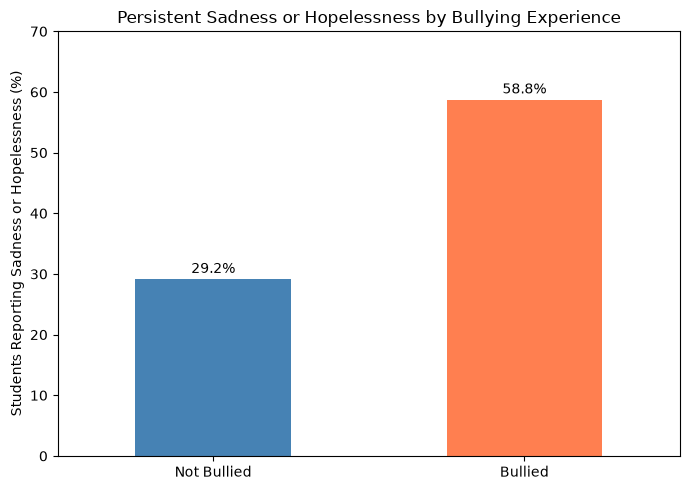

In [24]:
import matplotlib.pyplot as plt

sadness_by_bullying = (
    yrbs.groupby("bullied_at_school")["persistent_sadness"]
    .mean() * 100
)

sadness_by_bullying.index = ["Not Bullied", "Bullied"]

ax = sadness_by_bullying.plot(
    kind="bar",
    color=["steelblue", "coral"],
    figsize=(7, 5),
    rot=0
)

ax.set_title("Persistent Sadness or Hopelessness by Bullying Experience")
ax.set_xlabel("")
ax.set_ylabel("Students Reporting Sadness or Hopelessness (%)")
ax.set_ylim(0, 70)

for i, value in enumerate(sadness_by_bullying):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

Among students who reported being bullied at school, 58.8% also reported persistent sadness or hopelessness, compared with 29.2% of students who did not report being bullied. This represents a difference of 29.6 percentage points, suggesting a substantial association between in-person bullying and persistent sadness or hopelessness. These percentages are unweighted and exclude students with missing responses to either question. The observed association does not establish causation.

#### School Connectedness and Mental Health

I will now examine whether the frequency of poor mental health differs across levels of school connectedness. Because both variables have five ordered response categories, I will begin with a cross-tabulation to compare the distribution of mental health responses within each school connectedness category.

To make these differences easier to interpret, I will then calculate the percentage of students in each connectedness category who reported poor mental health "Most of the time" or "Always" (Q81 = 4 or 5). I will also calculate the percentage-point difference between students reporting the strongest and weakest school connectedness. Finally, I will use a line graph to visualize how the percentage reporting frequent poor mental health changes across the five levels of school connectedness.

In [25]:
pd.crosstab(
    yrbs["Q102"],
    yrbs["Q81"],
    normalize="index"
).mul(100).round(1)

Q81,1.0,2.0,3.0,4.0,5.0
Q102,,,,,
1.0,30.6,29.0,25.6,11.2,3.6
2.0,21.0,27.4,32.9,14.5,4.1
3.0,18.6,21.9,32.8,20.4,6.3
4.0,11.7,16.9,32.6,27.8,10.9
5.0,17.1,14.7,26.3,23.1,18.9


In [26]:
# Percentage reporting poor mental health most of the time or always
frequent_poor_mental_health = (
    pd.crosstab(yrbs["Q102"], yrbs["Q81"], normalize="index")
    [[4.0, 5.0]]
    .sum(axis=1) * 100
).round(1)

frequent_poor_mental_health.index = [
    "Strongly Agree", "Agree", "Neither",
    "Disagree", "Strongly Disagree"
]

frequent_poor_mental_health

Strongly Agree       14.8
Agree                18.6
Neither              26.7
Disagree             38.8
Strongly Disagree    42.0
dtype: float64

In [27]:
difference = (
    frequent_poor_mental_health["Strongly Disagree"]
    - frequent_poor_mental_health["Strongly Agree"]
)

print(f"Difference: {difference:.1f} percentage points")

Difference: 27.2 percentage points


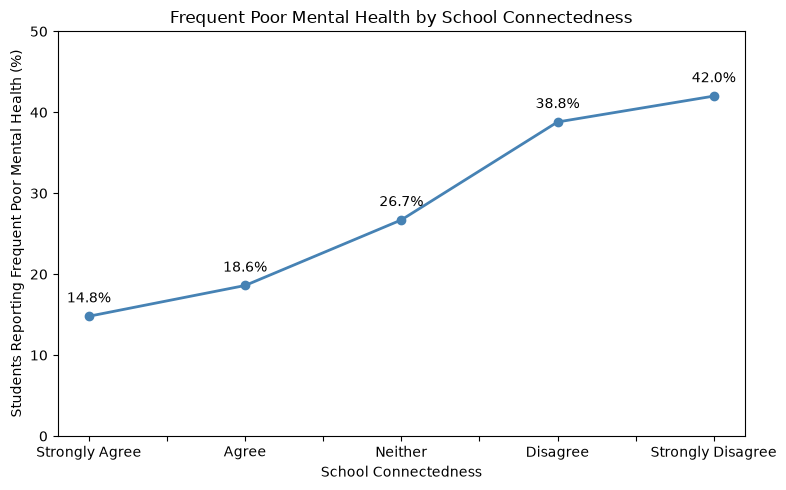

In [28]:
ax = frequent_poor_mental_health.plot(
    kind="line",
    marker="o",
    linewidth=2,
    figsize=(8, 5),
    color="steelblue"
)

ax.set_title("Frequent Poor Mental Health by School Connectedness")
ax.set_xlabel("School Connectedness")
ax.set_ylabel("Students Reporting Frequent Poor Mental Health (%)")
ax.set_ylim(0, 50)

for i, value in enumerate(frequent_poor_mental_health):
    ax.annotate(
        f"{value:.1f}%",
        (i, value),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The results suggest an association between lower school connectedness (higher Q102 values) and more frequent poor mental health (higher Q81 values). Among students who strongly agreed that they felt close to people at school, 14.8% reported poor mental health "Most of the time" or "Always," compared with 42.0% of students who strongly disagreed. This difference of 27.2 percentage points suggests that students reporting weaker school connectedness also tend to report more frequent poor mental health. These percentages are unweighted and exclude missing responses to either question. The association does not establish causation.

#### Bullying and Mental Health

I will examine how in-person and electronic bullying are associated with the frequency of poor mental health. For each type of bullying, I will compare the percentage of students reporting poor mental health "Most of the time" or "Always" (Q81 = 4 or 5) between those who experienced bullying and those who did not.

I will then use a grouped bar chart to visualize these differences and compare the associations between each type of bullying and frequent poor mental health.

In [30]:
# Create a binary indicator of frequent poor mental health
yrbs["frequent_poor_mental_health"] = (
    yrbs["Q81"].isin([4, 5]).where(yrbs["Q81"].notna())
)

# Compare percentages by bullying experience
bullying_mental_health = pd.DataFrame({
    "In-Person Bullying": (
        yrbs.groupby("bullied_at_school")["frequent_poor_mental_health"]
        .mean() * 100
    ),
    "Electronic Bullying": (
        yrbs.groupby("bullied_electronically")["frequent_poor_mental_health"]
        .mean() * 100
    )
})

bullying_mental_health.index = ["Not Bullied", "Bullied"]

bullying_mental_health.round(1)

,In-Person Bullying,Electronic Bullying
Not Bullied,18.921938,20.108408
Bullied,41.981424,42.170671


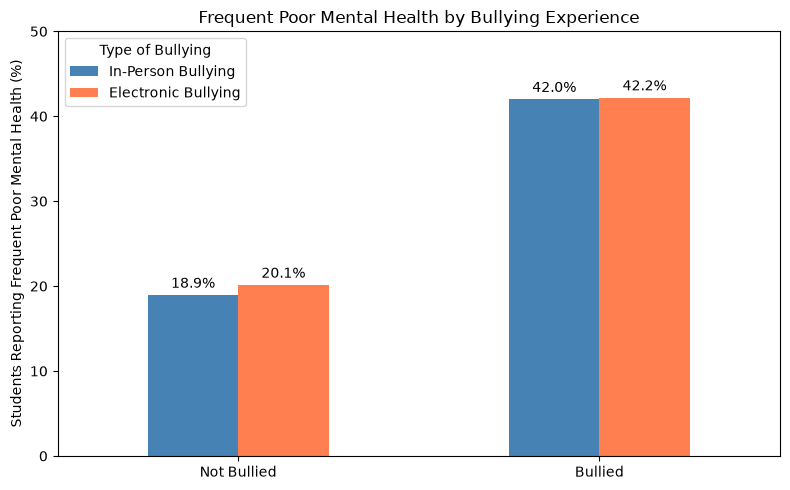

In [31]:
# Ensure values are numeric
bullying_mental_health = bullying_mental_health.astype(float)

ax = bullying_mental_health.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "coral"],
    rot=0
)

ax.set_title("Frequent Poor Mental Health by Bullying Experience")
ax.set_xlabel("")
ax.set_ylabel("Students Reporting Frequent Poor Mental Health (%)")
ax.set_ylim(0, 50)
ax.legend(title="Type of Bullying")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

Students who experienced either type of bullying reported substantially higher rates of frequent poor mental health than those who did not. Among students who experienced in-person bullying, 42.0% reported poor mental health "Most of the time" or "Always," compared with 18.9% of students who were not bullied at school, a difference of 23.1 percentage points. Similarly, 42.2% of students who experienced electronic bullying reported frequent poor mental health, compared with 20.1% of those who did not, a difference of 22.1 percentage points.

The associations were similar for both types of bullying. However, because students may have experienced both in-person and electronic bullying, these groups are not mutually exclusive. The percentages are unweighted, exclude missing responses, and do not establish causation.

#### School Safety and Mental Health

I will examine whether students who missed school because of safety concerns reported more frequent poor mental health than students who did not. Using the binary school safety variable (Q13), I will compare the percentage of students reporting poor mental health "Most of the time" or "Always" (Q81 = 4 or 5) between the two groups.

I will use a cross-tabulation to calculate the percentages within each group, followed by a bar chart to visualize the difference.

In [32]:
safety_mental_health = pd.crosstab(
    yrbs["missed_school_unsafe"],
    yrbs["frequent_poor_mental_health"],
    normalize="index"
).mul(100).round(1)

safety_mental_health.index = ["Did Not Miss School", "Missed School"]

safety_mental_health

frequent_poor_mental_health,False,True
Did Not Miss School,78.6,21.4
Missed School,63.7,36.3


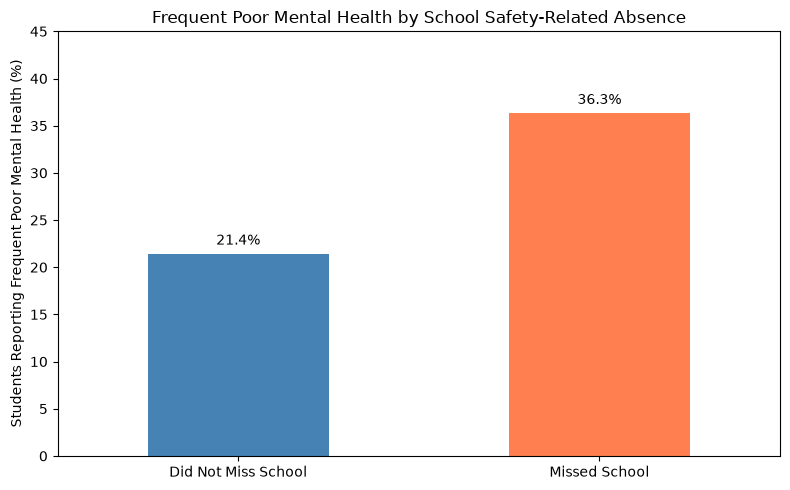

In [33]:
ax = safety_mental_health[True].plot(
    kind="bar",
    color=["steelblue", "coral"],
    figsize=(8, 5),
    rot=0
)

ax.set_title("Frequent Poor Mental Health by School Safety-Related Absence")
ax.set_xlabel("")
ax.set_ylabel("Students Reporting Frequent Poor Mental Health (%)")
ax.set_ylim(0, 45)

for i, value in enumerate(safety_mental_health[True]):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

Students who missed school at least once because of safety concerns reported higher rates of frequent poor mental health than students who did not. Among students who missed school for this reason, 36.3% reported poor mental health "Most of the time" or "Always," compared with 21.4% of students who did not miss school due to safety concerns. This represents a difference of 14.9 percentage points, suggesting an association between school safety-related absences and frequent poor mental health.

These percentages are unweighted and exclude students with missing responses to either question. The observed association does not establish causation.

## Statistical Analysis

### Hypotheses and Methods

I will use statistical hypothesis testing to evaluate the associations identified during exploratory data analysis. While the descriptive comparisons revealed differences between groups, hypothesis tests can help assess whether the observed differences provide evidence of associations under the assumptions of the selected statistical methods.

#### In-Person Bullying and Persistent Sadness or Hopelessness

I will begin by examining the relationship between in-person bullying and persistent sadness or hopelessness using a chi-square test of independence. This test is appropriate because both variables are categorical.

For this analysis, the hypotheses are:

- **Null hypothesis (H₀):** In-person bullying and persistent sadness or hopelessness are independent.

- **Alternative hypothesis (H₁):** In-person bullying and persistent sadness or hopelessness are associated.

I will use a significance level of α = 0.05. Because these initial tests do not account for the YRBS complex survey design or sampling weights, their results will be interpreted as exploratory rather than as definitive population-level inference.

In [34]:
bullying_sadness_counts = pd.crosstab(
    yrbs["bullied_at_school"],
    yrbs["persistent_sadness"]
)

bullying_sadness_counts

persistent_sadness,0.0,1.0
bullied_at_school,,
0.0,6044,2489
1.0,791,1127


In [35]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(bullying_sadness_counts)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4g}")

Chi-square statistic: 604.64
Degrees of freedom: 1
P-value: 1.642e-133


The chi-square test produced a statistic of 604.64 with 1 degree of freedom and a p-value of approximately 1.64 × 10⁻¹³³. Because the p-value is below the significance threshold of 0.05, I reject the null hypothesis of independence. The results provide strong evidence of an association between in-person bullying and persistent sadness or hopelessness under the assumptions of the standard chi-square test.

This finding is consistent with the descriptive analysis, which showed substantially higher rates of persistent sadness or hopelessness among students who experienced bullying. However, the test does not account for the YRBS complex survey design or sampling weights, so the statistical significance should be interpreted cautiously. The association also does not establish causation.

#### School Connectedness and Poor Mental Health

Next, I will examine the association between school connectedness (Q102) and frequency of poor mental health (Q81) using Spearman's rank correlation. This method is appropriate because both variables have ordered response categories.

- **Null hypothesis (H₀):** There is no monotonic association between school connectedness responses and poor mental health frequency. 
- **Alternative hypothesis (H₁):** An association exists. 

I will use a significance level of α = 0.05.

In [36]:
from scipy.stats import spearmanr

connectedness_mental_health = yrbs[["Q102", "Q81"]].dropna()

rho, p_value = spearmanr(
    connectedness_mental_health["Q102"],
    connectedness_mental_health["Q81"]
)

print(f"Spearman's rho: {rho:.3f}")
print(f"P-value: {p_value:.4g}")
print(f"Valid responses: {len(connectedness_mental_health)}")

Spearman's rho: 0.214
P-value: 8.418e-85
Valid responses: 8113


Spearman's rank correlation produced a coefficient of ρ = 0.214 with a p-value of approximately 8.42 × 10⁻⁸⁵, based on 8,113 students with valid responses to both questions. The positive coefficient indicates a weak association in which students reporting lower school connectedness tend to report more frequent poor mental health.

Because the p-value is below 0.05, I reject the null hypothesis of no monotonic association under the assumptions of the standard test. This result is consistent with the pattern observed during exploratory data analysis. However, the test does not account for the YRBS complex survey design or sampling weights, and the association does not establish causation.

#### Bullying and Frequent Poor Mental Health

I will use chi-square tests of independence to examine whether in-person and electronic bullying are associated with frequent poor mental health (Q81 = 4 or 5). I will conduct a separate test for each type of bullying.

For each test, the hypotheses are:

- **Null hypothesis (H₀):** Bullying experience and frequent poor mental health are independent.

-  **Alternative hypothesis (H₁):** Bullying experience and frequent poor mental health are associated.

I will use a significance level of α = 0.05.

In [37]:
in_person_counts = pd.crosstab(
    yrbs["bullied_at_school"],
    yrbs["frequent_poor_mental_health"]
)

electronic_counts = pd.crosstab(
    yrbs["bullied_electronically"],
    yrbs["frequent_poor_mental_health"]
)

print("In-Person Bullying:")
print(in_person_counts)

print("\nElectronic Bullying:")
print(electronic_counts)

In-Person Bullying:
frequent_poor_mental_health  False  True 
bullied_at_school                        
0.0                           5806   1355
1.0                            937    678

Electronic Bullying:
frequent_poor_mental_health  False  True 
bullied_electronically                   
0.0                           6043   1521
1.0                            698    509


In [38]:
for label, counts in {
    "In-Person Bullying": in_person_counts,
    "Electronic Bullying": electronic_counts
}.items():
    chi2, p_value, dof, expected = chi2_contingency(counts)

    print(f"{label}:")
    print(f"Chi-square statistic: {chi2:.2f}")
    print(f"Degrees of freedom: {dof}")
    print(f"P-value: {p_value:.4g}")
    print()

In-Person Bullying:
Chi-square statistic: 392.39
Degrees of freedom: 1
P-value: 2.494e-87

Electronic Bullying:
Chi-square statistic: 283.59
Degrees of freedom: 1
P-value: 1.238e-63



Both chi-square tests produced p-values substantially below the significance threshold of 0.05. The test for in-person bullying yielded χ²(1) = 392.39 (p ≈ 2.49 × 10⁻⁸⁷), while the test for electronic bullying yielded χ²(1) = 283.59 (p ≈ 1.24 × 10⁻⁶³). I therefore reject the null hypothesis of independence for both comparisons.

These findings are consistent with the exploratory analysis, in which approximately 42% of students experiencing either type of bullying reported frequent poor mental health, compared with approximately 19–20% of students who did not report the corresponding type of bullying.

Because these tests do not account for the YRBS complex survey design or sampling weights, the p-values should be interpreted as exploratory. The results do not establish causation or determine which type of bullying has a stronger independent association with poor mental health.

#### School Safety and Frequent Poor Mental Health

Finally, I will use a chi-square test of independence to examine whether school safety-related absences are associated with frequent poor mental health.

The hypotheses are:

- **Null hypothesis (H₀):** School safety-related absences and frequent poor mental health are independent.

- **Alternative hypothesis (H₁):** School safety-related absences and frequent poor mental health are associated.

I will use a significance level of α = 0.05.

In [39]:
safety_counts = pd.crosstab(
    yrbs["missed_school_unsafe"],
    yrbs["frequent_poor_mental_health"]
)

safety_counts

frequent_poor_mental_health,False,True
missed_school_unsafe,,
0.0,6058,1649
1.0,673,384


In [40]:
chi2, p_value, dof, expected = chi2_contingency(safety_counts)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4g}")

Chi-square statistic: 115.51
Degrees of freedom: 1
P-value: 6.092e-27


The chi-square test produced a statistic of 115.51 with 1 degree of freedom and a p-value of approximately 6.09 × 10⁻²⁷. Because the p-value is below the significance threshold of 0.05, I reject the null hypothesis of independence.

This finding is consistent with the exploratory analysis, which showed that 36.3% of students who missed school because of safety concerns reported frequent poor mental health, compared with 21.4% of students who did not. The difference of 14.9 percentage points suggests an association between school safety-related absences and frequent poor mental health.

However, the test does not account for the YRBS complex survey design or sampling weights, so the statistical significance should be interpreted cautiously. The association does not establish causation.

## Discussion and Conclusions

### Key Findings

The analysis identified several associations between students' experiences at school and their mental health.

**Bullying and mental health:** Students who reported in-person bullying were substantially more likely to report persistent sadness or hopelessness (58.8%) than students who did not report bullying (29.2%). Similarly, approximately 42% of students experiencing either in-person or electronic bullying reported frequent poor mental health, compared with approximately 19–20% of students who did not report the corresponding type of bullying.

**School connectedness:** Students reporting weaker school connectedness also tended to report more frequent poor mental health. Among students who strongly agreed that they felt close to people at school, 14.8% reported frequent poor mental health, compared with 42.0% of those who strongly disagreed. Spearman's rank correlation indicated a weak positive association (ρ = 0.214), consistent with this pattern.

**School safety:** Students who missed school because of safety concerns reported frequent poor mental health at a higher rate (36.3%) than students who did not miss school for this reason (21.4%).

All five hypothesis tests produced p-values below 0.05 under their standard assumptions. Together, these findings suggest that bullying, perceived school connectedness, and school safety-related absences are associated with students' reported mental health.

### Limitations and Implications

Several limitations should be considered when interpreting these findings.

**Survey design and weighting:** The analyses used unweighted responses and did not account for the YRBS complex sampling design. Consequently, the reported percentages should be interpreted as descriptive statistics for the surveyed students rather than nationally representative estimates. Similarly, the hypothesis tests were not adjusted for the survey design, limiting the reliability of population-level statistical inferences.

**Missing data:** Missing responses were particularly substantial for poor mental health (Q81, 17.8%) and school connectedness (Q102, 12.0%). Missingness also varied across grade levels and racial/ethnic groups, raising concerns about potential nonresponse bias. If students who did not answer these questions differ systematically from those who did, the observed relationships may not accurately represent the broader student population.

**Self-reported responses:** The survey relies on students' self-reported experiences, which may be influenced by differences in interpretation, recall, or willingness to disclose sensitive information.

**Causation:** Because the data are observational and cross-sectional, the associations identified in this analysis do not establish causal relationships. For example, while students reporting weaker school connectedness also reported more frequent poor mental health, the analysis cannot determine whether one contributes to the other or whether additional factors influence both.

**Implications:** Despite these limitations, the findings highlight the value of examining students' experiences of bullying, school safety, and connectedness alongside measures of mental health. Schools could use similar survey analyses to identify areas that warrant further investigation, incorporate student perspectives into decision-making, and evaluate whether efforts to improve school climate are associated with changes in student experiences over time.